# Maksymalny prąd w układzie rezystorów - programowanie liniowe

**Cel ćwiczenia:** zapisać obwód jako układ liniowych równań i ograniczeń, a następnie znaleźć maksymalny prąd zasilania przy użyciu `scipy.optimize.linprog`.

Układ składa się z trzech połączonych szeregowo części: $R_1\parallel R_2$, rezystora $R_3$ oraz $R_4\parallel R_5$. Poniższy schemat jest rysowany bezpośrednio w Pythonie, dzięki czemu można go wyświetlić w Jupyter Notebook bez zewnętrznych plików graficznych.

**Dane wejściowe:**

| Rezystor | Rezystancja [Ω] | Maksymalny prąd [A] |
|:---:|---:|---:|
| $R_1$ | 8 | 2 |
| $R_2$ | 6 | 3 |
| $R_3$ | 4 | 4 |
| $R_4$ | 10 | 2 |
| $R_5$ | 8 | 2 |

**Założenie:** napięcie zasilania może być regulowane. Prądy płyną od lewej do prawej, a ich wartości są nieujemne. Szukamy największego dopuszczalnego prądu całego obwodu.

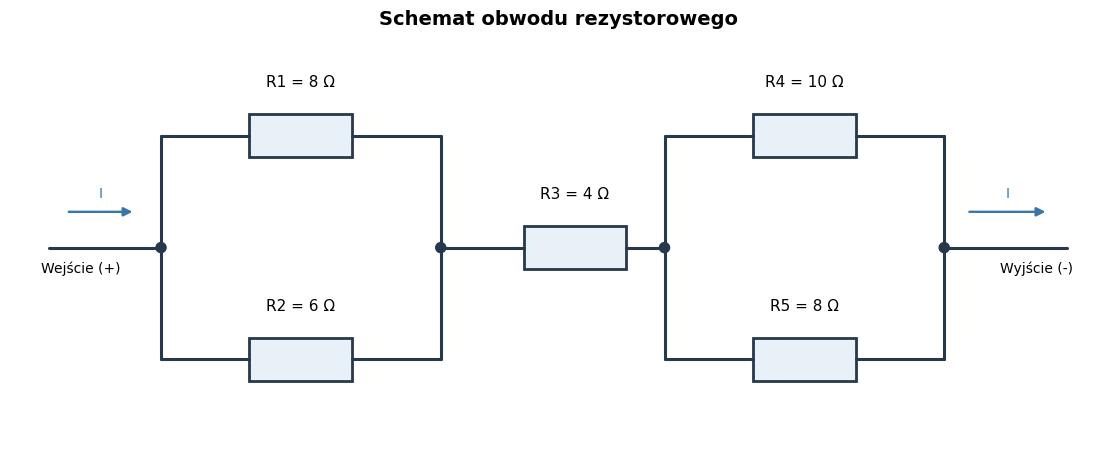

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, FancyArrowPatch, Circle

# Schemat ideowy ukladu z dwoma polaczeniami rownoleglymi
def rysuj_schemat(R, I=None):
    fig, ax = plt.subplots(figsize=(13, 4.7))
    kolor_przewodu = '#26384b'
    kolor_rezystora = '#e8f0f8'
    kolor_limitu = '#a23a35'
    grubosc = 2.2

    def przewod(x1, y1, x2, y2):
        ax.plot([x1, x2], [y1, y2], color=kolor_przewodu, lw=grubosc, solid_capstyle='round')

    def rezystor(x, y, numer, szerokosc=0.92):
        wysokosc = 0.38
        ax.add_patch(Rectangle((x-szerokosc/2, y-wysokosc/2), szerokosc, wysokosc,
                               facecolor=kolor_rezystora, edgecolor=kolor_przewodu, lw=2))
        ax.text(x, y+0.42, f'R{numer} = {R[numer-1]:g} Ω', ha='center', va='bottom', fontsize=11)
        if I is not None:
            ax.text(x, y-0.44, f'I{numer} = {I[numer-1]:.3f} A', ha='center', va='top',
                    fontsize=10, color=kolor_limitu if numer==5 else '#315f88')
        return x-szerokosc/2, x+szerokosc/2

    def wezel(x, y):
        ax.add_patch(Circle((x,y), 0.045, color=kolor_przewodu, zorder=5))

    def strzalka(x1, x2, y, etykieta):
        ax.add_patch(FancyArrowPatch((x1,y), (x2,y), arrowstyle='-|>',
                                     mutation_scale=13, color='#3777a8', lw=1.7))
        ax.text((x1+x2)/2, y+0.13, etykieta, color='#3777a8', ha='center', fontsize=10)

    # Lewa sekcja rownolegla
    przewod(0.15, 0, 1.15, 0)
    przewod(1.15, -1, 1.15, 1)
    przewod(3.65, -1, 3.65, 1)
    for numer, y in [(1,1),(2,-1)]:
        a,b=rezystor(2.4, y, numer)
        przewod(1.15,y,a,y)
        przewod(b,y,3.65,y)
    przewod(3.65,0,4.3,0)
    for x in (1.15,3.65): wezel(x,0)

    # Srodkowy rezystor
    a,b=rezystor(4.85,0,3)
    przewod(4.3,0,a,0)
    przewod(b,0,5.65,0)

    # Prawa sekcja rownolegla
    przewod(5.65, -1, 5.65, 1)
    przewod(8.15, -1, 8.15, 1)
    for numer,y in [(4,1),(5,-1)]:
        a,b=rezystor(6.9,y,numer)
        przewod(5.65,y,a,y)
        przewod(b,y,8.15,y)
    przewod(8.15,0,9.25,0)
    for x in (5.65,8.15): wezel(x,0)

    strzalka(0.30, 0.92, 0.32, 'I')
    strzalka(8.35, 9.08, 0.32, 'I')
    ax.text(0.08,-0.22,'Wejście (+)',ha='left',fontsize=10)
    ax.text(9.3,-0.22,'Wyjście (-)',ha='right',fontsize=10)
    ax.set_xlim(-0.2,9.6)
    ax.set_ylim(-1.8,1.8)
    ax.set_aspect('equal')
    ax.axis('off')
    ax.set_title('Schemat obwodu rezystorowego', fontsize=14, pad=16, weight='bold')
    plt.tight_layout()
    plt.show()

R_schemat = [8, 6, 4, 10, 8]
rysuj_schemat(R_schemat)


## 1. Wybór zmiennych decyzyjnych

Niech wektor niewiadomych ma postać

$$
\mathbf{x}=\begin{bmatrix}I_1&I_2&I_3&I_4&I_5\end{bmatrix}^{T}.
$$

Ponieważ rezystor R3 leży w gałęzi szeregowej, **prąd całego układu to $I=I_3$**. Maksymalizujemy zatem $I_3$.

### Prawa Kirchhoffa — bilans prądów

W węzłach przed i za R3:

$$
I_1+I_2=I_3,\qquad I_3=I_4+I_5.
$$

### Prawo Ohma — jednakowe napięcie na gałęziach równoległych

R1 i R2 są równoległe, a więc ich spadki napięcia są identyczne:

$$
R_1 I_1=R_2 I_2 \quad\Rightarrow\quad 8I_1-6I_2=0.
$$

Podobnie dla R4 i R5:

$$
R_4 I_4=R_5 I_5 \quad\Rightarrow\quad 10I_4-8I_5=0.
$$

### Ograniczenia obciążalności

$$
0\le I_1\le2,\quad 0\le I_2\le3,\quad 0\le I_3\le4,
\quad 0\le I_4\le2,\quad 0\le I_5\le2.
$$

Dostaliśmy **program liniowy (LP)**: liniową funkcję celu, cztery liniowe równania i ograniczenia przedziałowe.

## 2. Macierzowa postać zagadnienia

`linprog` rozwiązuje problem **minimalizacji**. Maksymalizację $I_3$ zapisujemy więc jako minimalizację $-I_3$:

$$
\min_{\mathbf{x}} \mathbf{c}^T\mathbf{x},\qquad
\mathbf{c}=\begin{bmatrix}0&0&-1&0&0\end{bmatrix}^{T}.
$$

Równania $A_{eq}\mathbf{x}=\mathbf{b}_{eq}$ mają postać:

$$
\underbrace{\begin{bmatrix}
1&1&-1&0&0\\
0&0&1&-1&-1\\
8&-6&0&0&0\\
0&0&0&10&-8
\end{bmatrix}}_{A_{eq}}
\begin{bmatrix}I_1\\I_2\\I_3\\I_4\\I_5\end{bmatrix}
=
\underbrace{\begin{bmatrix}0\\0\\0\\0\end{bmatrix}}_{\mathbf{b}_{eq}}.
$$

Każdy **wiersz macierzy** odpowiada jednemu prawu fizycznemu. Ograniczenia $0\le I_k\le I_{k,\max}$ przekazujemy osobno jako `bounds`.

In [ ]:
import numpy as np
import pandas as pd
from scipy.optimize import linprog

# Dane wejsciowe
nazwy = ["R1", "R2", "R3", "R4", "R5"]
R = np.array([8.0, 6.0, 4.0, 10.0, 8.0])
I_max = np.array([2.0, 3.0, 4.0, 2.0, 2.0])

# Funkcja celu: minimalizacja -I3 oznacza maksymalizacje I3
c = np.array([0.0, 0.0, -1.0, 0.0, 0.0])

# Rownania: dwa prawa Kirchhoffa i dwa rownania napiec
A_eq = np.array([
    [1.0,  1.0, -1.0,  0.0,  0.0],
    [0.0,  0.0,  1.0, -1.0, -1.0],
    [R[0], -R[1], 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0, R[3], -R[4]],
])
b_eq = np.zeros(4)

# Zakresy wszystkich pradow: od zera do limitu
bounds = [(0.0, limit) for limit in I_max]

print("Macierz A_eq:\n", A_eq)
print("Wektor b_eq:", b_eq)
print("Wektor c:", c)
print("Ograniczenia:", bounds)

Macierz A_eq:
 [[ 1.  1. -1.  0.  0.]
 [ 0.  0.  1. -1. -1.]
 [ 8. -6.  0.  0.  0.]
 [ 0.  0.  0. 10. -8.]]
Wektor b_eq: [0. 0. 0. 0.]
Wektor c: [ 0.  0. -1.  0.  0.]
Ograniczenia: [(0.0, np.float64(2.0)), (0.0, np.float64(3.0)), (0.0, np.float64(4.0)), (0.0, np.float64(2.0)), (0.0, np.float64(2.0))]


## 3. Obliczenie optimum za pomocą solvera

Solver znajduje prądy spełniające jednocześnie wszystkie równania fizyczne i limity, a spośród nich wybiera te o największym `I3`.

In [ ]:
wynik = linprog(c, A_eq=A_eq, b_eq=b_eq, bounds=bounds, method="highs")
if not wynik.success:
    raise RuntimeError(f"Nie udalo sie rozwiazac problemu: {wynik.message}")

I = wynik.x
I_calkowity = I[2]

zestawienie = pd.DataFrame({
    "Rezystor": nazwy,
    "R [ohm]": R,
    "I [A]": I,
    "Limit [A]": I_max,
    "Zapas [A]": I_max - I,
    "Wykorzystanie [%]": 100 * I / I_max,
})
print(f"Maksymalny prad calego ukladu: {I_calkowity:.6f} A")
print(zestawienie.to_string(index=False, float_format=lambda x: f"{x:.6f}"))

Maksymalny prad calego ukladu: 3.600000 A
Rezystor   R [ohm]    I [A]  Limit [A]  Zapas [A]  Wykorzystanie [%]
      R1  8.000000 1.542857   2.000000   0.457143          77.142857
      R2  6.000000 2.057143   3.000000   0.942857          68.571429
      R3  4.000000 3.600000   4.000000   0.400000          90.000000
      R4 10.000000 1.600000   2.000000   0.400000          80.000000
      R5  8.000000 2.000000   2.000000   0.000000         100.000000


### Rozkład prądów przy maksymalnym obciążeniu

Po rozwiązaniu wyświetlamy ten sam schemat z prądem w każdym rezystorze.

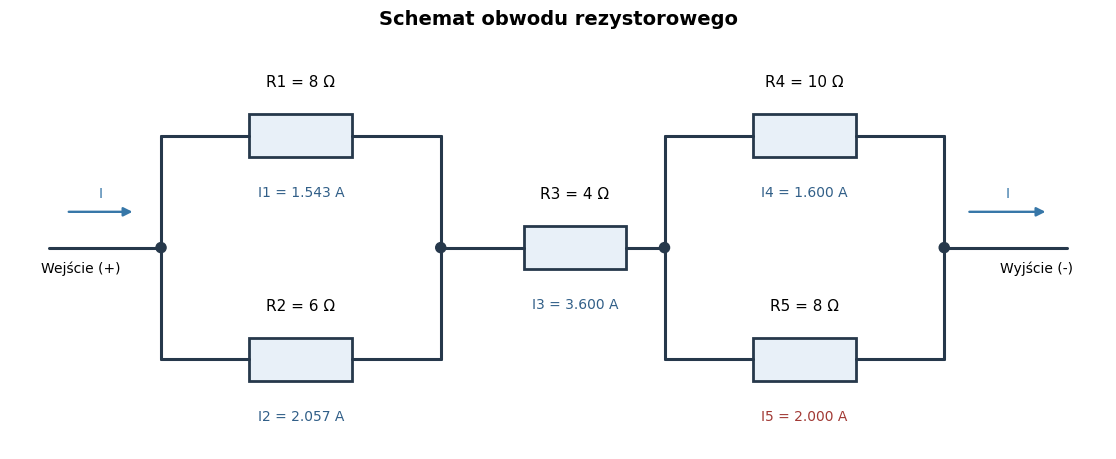

In [ ]:
rysuj_schemat(R, I)

## 4. Dlaczego właśnie taka wartość? Wyprowadzenie bez solvera

Warto pokazać, dlaczego program liniowy daje ten wynik.

Dla lewej pary (R1 i R2):

$$
I_1+I_2=I_3,\qquad 8I_1=6I_2
$$

stąd

$$
I_1=\frac{3}{7}I_3,\qquad I_2=\frac{4}{7}I_3.
$$

Dla prawej pary (R4 i R5):

$$
I_4+I_5=I_3,\qquad 10I_4=8I_5
$$

stąd

$$
I_4=\frac{4}{9}I_3,\qquad I_5=\frac{5}{9}I_3.
$$

Podstawiając limity dla poszczególnych rezystorów, otrzymujemy pięć niezależnych górnych granic prądu całkowitego:

$$
I_3\le\frac{14}{3}\;(R1),\quad
I_3\le\frac{21}{4}\;(R2),\quad
I_3\le4\;(R3),\quad
I_3\le\frac{9}{2}\;(R4),\quad
I_3\le\frac{18}{5}\;(R5).
$$

**Najmniejsza z tych granic jest wiążąca:** to ten element jako pierwszy osiąga maksymalny dopuszczalny prąd. To właśnie ogranicza cały obwód.

## 6. Podsumowanie metody

**Wniosek:** układ elektryczny można sprowadzić do programu liniowego bez zastępowania go rezystancją zastępczą. Rezystancja zastępcza może służyć do niezależnego sprawdzenia obliczonego napięcia.